# Lead Scoring — Exploratory Data Analysis

Dataset: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). Each row is a unique customer, described only by their **first order**, with a target flag for whether they went on to place a **second (repeat) order**.

This notebook checks which first-order signals, if any, actually predict repeat-purchase propensity — before building any model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Portfolio design tokens (design-tokens.md): blue accent, white background
COLOR_BG = "#FFFFFF"
COLOR_ACCENT = "#1D5FD6"
COLOR_ACCENT_HOVER = "#164BAD"
COLOR_ACCENT_LIGHT = "#E8F0FE"
COLOR_TEXT_PRIMARY = "#0B1F33"
COLOR_TEXT_SECONDARY = "#4A5B6E"
COLOR_BORDER = "#D7E3F0"
COLOR_WARNING = "#9A5B0C"
COLOR_DANGER = "#C53030"

plt.rcParams.update({
    "figure.facecolor": COLOR_BG,
    "axes.facecolor": COLOR_BG,
    "axes.edgecolor": COLOR_BORDER,
    "axes.labelcolor": COLOR_TEXT_PRIMARY,
    "text.color": COLOR_TEXT_PRIMARY,
    "xtick.color": COLOR_TEXT_SECONDARY,
    "ytick.color": COLOR_TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": COLOR_BORDER,
    "grid.linewidth": 0.6,
    "font.family": "sans-serif",
    "font.size": 11,
})

FIG_DIR = Path("..") / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../data/processed/customer_first_order_features.csv")
print(f"{len(df):,} customers, repeat-purchase rate: {df['target_repeat_purchase'].mean()*100:.2f}%")

94,990 customers, repeat-purchase rate: 3.04%


## 1. The target is heavily imbalanced

Only ~3% of customers ever place a second order. This alone shapes every modeling decision downstream: accuracy is a useless metric, and the model needs class-imbalance handling (`scale_pos_weight` / `class_weights`).

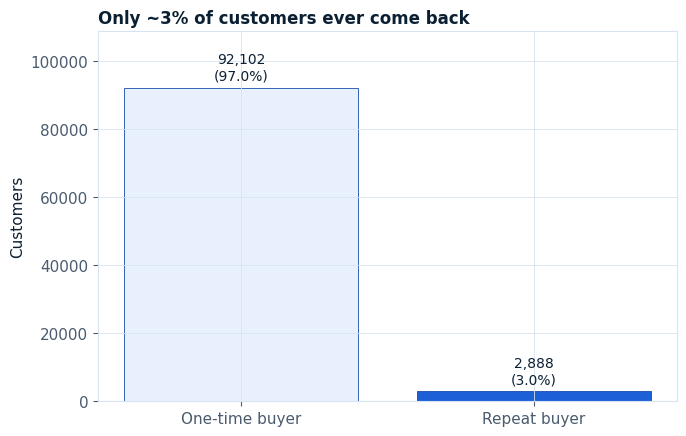

In [2]:
counts = df["target_repeat_purchase"].value_counts().sort_index()
labels = ["One-time buyer", "Repeat buyer"]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, counts.values, color=[COLOR_ACCENT_LIGHT, COLOR_ACCENT], edgecolor=COLOR_ACCENT_HOVER, linewidth=0.6)
for bar, count in zip(bars, counts.values):
    ax.annotate(f"{count:,}\n({count/len(df)*100:.1f}%)", xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
                xytext=(0, 6), textcoords="offset points", ha="center", fontsize=10)
ax.set_ylim(top=counts.max() * 1.18)
ax.set_ylabel("Customers")
ax.set_title("Only ~3% of customers ever come back", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_class_imbalance.png", dpi=150)
plt.show()

## 2. First-order basket size is the strongest single signal

Customers who bought more items in their first order come back at a notably higher rate — a nearly 3x spread between a 1-item and a 6-item first basket.

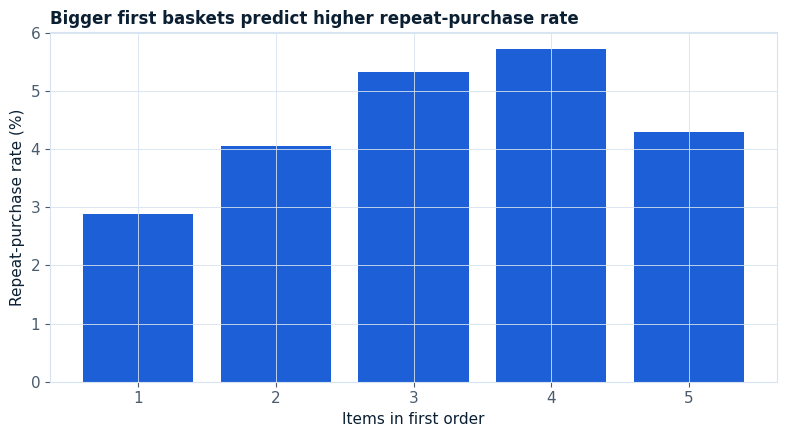

             mean   size
n_items                 
1.0      0.028918  85655
2.0      0.040462   7192
3.0      0.053312   1238
4.0      0.057203    472
5.0      0.043011    186


In [3]:
basket = df[df["n_items"] <= 5].groupby("n_items")["target_repeat_purchase"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(basket.index.astype(int).astype(str), basket["mean"] * 100, color=COLOR_ACCENT)
ax.set_xlabel("Items in first order")
ax.set_ylabel("Repeat-purchase rate (%)")
ax.set_title("Bigger first baskets predict higher repeat-purchase rate", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_basket_size_vs_repeat.png", dpi=150)
plt.show()

print(basket)

## 3. Category matters, but modestly

Repeat rate by primary product category (top 10 by volume) — a real but modest spread, with home/furniture categories outperforming electronics and novelty items.

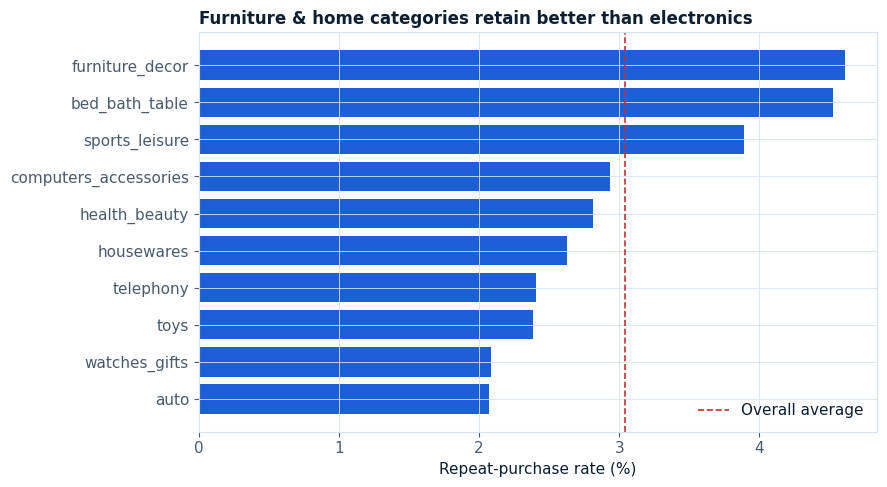

In [4]:
top_cats = df["primary_category"].value_counts().head(10).index
cat_rate = (
    df[df["primary_category"].isin(top_cats)]
    .groupby("primary_category")["target_repeat_purchase"]
    .mean()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(cat_rate.index, cat_rate.values * 100, color=COLOR_ACCENT)
ax.axvline(df["target_repeat_purchase"].mean() * 100, color=COLOR_DANGER, linestyle="--", linewidth=1.2, label="Overall average")
ax.set_xlabel("Repeat-purchase rate (%)")
ax.set_title("Furniture & home categories retain better than electronics", loc="left", fontsize=12, fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_category_vs_repeat.png", dpi=150)
plt.show()

## 4. Review score barely moves the needle

A good first-order experience should intuitively drive loyalty — but the actual relationship is weak and non-monotonic. This is a useful negative result: satisfaction alone doesn't explain repeat behavior in this data.

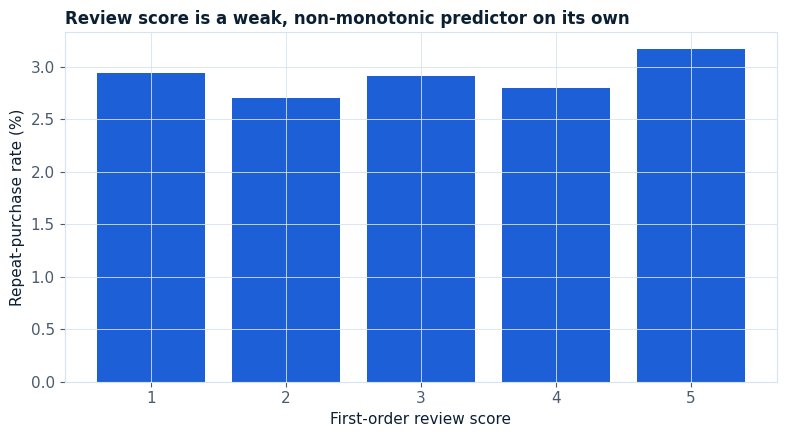

review_score
1.0    0.029409
2.0    0.027073
3.0    0.029159
4.0    0.027943
5.0    0.031703
Name: target_repeat_purchase, dtype: float64


In [5]:
review_rate = df.dropna(subset=["review_score"]).groupby("review_score")["target_repeat_purchase"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(review_rate.index.astype(int).astype(str), review_rate.values * 100, color=COLOR_ACCENT)
ax.set_xlabel("First-order review score")
ax.set_ylabel("Repeat-purchase rate (%)")
ax.set_title("Review score is a weak, non-monotonic predictor on its own", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_review_score_vs_repeat.png", dpi=150)
plt.show()

print(review_rate)

## Key findings

1. **Severe class imbalance**: only 3.04% of customers return for a second order — any model here must be evaluated with PR-AUC/ROC-AUC, not accuracy, and trained with class-weighting.
2. **Basket size is the clearest single lever**: customers buying 4+ items in their first order repeat at roughly double the rate of single-item buyers — a strong, actionable, real signal.
3. **Category effects are real but modest**: furniture/home categories retain noticeably better than electronics/novelty categories, a ~2.5x spread between the extremes.
4. **No single feature is a strong standalone predictor** — even review score, the most intuitive lever, is weak and non-monotonic. This motivates a multivariate model over simple business rules, and sets a realistic expectation: this is a hard, low-signal-to-noise problem, common in real retention/CRM data.